# Golub Dataset: Exploratory Data Analysis

## 1. Reproducibility Setup

In [16]:
import random
import numpy as np

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

## 2. Golub Dataset Loading and Initial Inspection

In [17]:
import kagglehub

path = kagglehub.dataset_download("crawford/gene-expression")
print(path)

C:\Users\zehra\.cache\kagglehub\datasets\crawford\gene-expression\versions\3


In [18]:
from pathlib import Path

files = list(Path(path).rglob("*"))

for file in files:
    if file.is_file():
        print(file.name, "—", file.stat().st_size, "bytes")

actual.csv — 511 bytes
data_set_ALL_AML_independent.csv — 1860352 bytes
data_set_ALL_AML_train.csv — 2039681 bytes


In [19]:
import pandas as pd

data_path = Path(path)

train = pd.read_csv(data_path / "data_set_ALL_AML_train.csv")
test = pd.read_csv(data_path / "data_set_ALL_AML_independent.csv")
actual = pd.read_csv(data_path / "actual.csv")

print("Train:", train.shape)
print("Test:", test.shape)
print("Labels:", actual.shape)

print("\nTrain columns:", train.columns[:10].tolist())
print("\nLabels preview:")
print(actual.head())

Train: (7129, 78)
Test: (7129, 70)
Labels: (72, 2)

Train columns: ['Gene Description', 'Gene Accession Number', '1', 'call', '2', 'call.1', '3', 'call.2', '4', 'call.3']

Labels preview:
   patient cancer
0        1    ALL
1        2    ALL
2        3    ALL
3        4    ALL
4        5    ALL


## 3. Expression Matrix Preparation and Diagnosis Labels

In [20]:
train_patients = [col for col in train.columns if col.isdigit()]
test_patients = [col for col in test.columns if col.isdigit()]

print("Training patients:", len(train_patients))
print("Test patients:", len(test_patients))

print("Train IDs:", train_patients)
print("Test IDs:", test_patients)

Training patients: 38
Test patients: 34
Train IDs: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '34', '35', '36', '37', '38', '28', '29', '30', '31', '32', '33']
Test IDs: ['39', '40', '42', '47', '48', '49', '41', '43', '44', '45', '46', '70', '71', '72', '68', '69', '67', '55', '56', '59', '52', '53', '51', '50', '54', '57', '58', '60', '61', '65', '66', '63', '64', '62']


In [21]:
# Keep expression columns only
train_expr = train[train_patients].T
test_expr = test[test_patients].T

# Convert patient IDs to integers
train_expr.index = train_expr.index.astype(int)
test_expr.index = test_expr.index.astype(int)

# Sort patients by ID
train_expr = train_expr.sort_index()
test_expr = test_expr.sort_index()


In [22]:
# Encode ALL = 1, AML = 0
actual["cancer"] = actual["cancer"].map({"ALL": 1, "AML": 0})

In [23]:
# Attach labels using patient IDs
train_expr["target"] = actual.set_index("patient").loc[train_expr.index, "cancer"]
test_expr["target"] = actual.set_index("patient").loc[test_expr.index, "cancer"]

print("Train:", train_expr.shape)
print("Test:", test_expr.shape)
print("Train labels:", train_expr["target"].value_counts())
print("Test labels:", test_expr["target"].value_counts())

Train: (38, 7130)
Test: (34, 7130)
Train labels: target
1    27
0    11
Name: count, dtype: int64
Test labels: target
1    20
0    14
Name: count, dtype: int64


## 4. Data Quality and Descriptive Statistics

In [24]:
X_train = train_expr.drop(columns="target")
X_test = test_expr.drop(columns="target")

In [25]:

import numpy as np
import pandas as pd

def data_quality_report(train_expr, test_expr):
    

    datasets = {
        "Training": X_train,
        "Held-out test": X_test
    }

    quality = {}
    statistics = {}

    for name, df in datasets.items():
        # Ensure that all expression features are numeric
        X = df.apply(pd.to_numeric, errors="raise")
        values = X.to_numpy(dtype=float)

        quality[name] = {
            "Samples": X.shape[0],
            "Features": X.shape[1],
            "Missing values": int(np.isnan(values).sum()),
            "Infinite values": int(np.isinf(values).sum()),
            "Negative values": int((values < 0).sum()),
            "Zero values": int((values == 0).sum()),
            "Duplicate samples": int(X.duplicated().sum()),
            "Constant features": int(
                (X.nunique(dropna=False) <= 1).sum()
            )
        }

        # Descriptive statistics across all expression values
        flat = values.ravel()
        flat = flat[np.isfinite(flat)]

        statistics[name] = pd.Series(flat).describe(
            percentiles=[0.25, 0.50, 0.75, 0.99, 0.999]
        )

    print("=== DATA QUALITY ===")
    display(pd.DataFrame(quality))

    print("\n=== DESCRIPTIVE STATISTICS ===")
    display(pd.DataFrame(statistics).round(3))

data_quality_report(X_train, X_test)


=== DATA QUALITY ===


,Training,Held-out test
Samples,38,34
Features,7129,7129
Missing values,0,0
Infinite values,0,0
Negative values,77175,69999
Zero values,738,877
Duplicate samples,0,0
Constant features,0,0



=== DESCRIPTIVE STATISTICS ===


,Training,Held-out test
count,270902.000,242386.000
mean,637.698,599.751
std,2426.223,2459.492
min,-28400.000,-26775.000
25%,-20.000,-21.000
50%,127.000,114.000
75%,466.000,410.000
99%,15061.970,14332.450
99.9%,24322.495,27127.840
max,61228.000,71369.000


In [26]:
for name, X in [("Train", X_train), ("Test", X_test)]:
    values = X.to_numpy()

    print(f"\n--- {name} Descriptive Statistics ---")
    print("Negative values:", (values < 0).sum())
    print("Zero values:", (values == 0).sum())
    print("Minimum:", values.min())
    print("Maximum:", values.max())
    print("Mean:", values.mean())
    print("Median:", np.median(values))
    print("Standard deviation:", values.std())


--- Train Descriptive Statistics ---
Negative values: 77175
Zero values: 738
Minimum: -28400
Maximum: 61228
Mean: 637.6980014913142
Median: 127.0
Standard deviation: 2426.2181600967137

--- Test Descriptive Statistics ---
Negative values: 69999
Zero values: 877
Minimum: -26775
Maximum: 71369
Mean: 599.7512686376276
Median: 114.0
Standard deviation: 2459.487294363926


## 5. Raw Expression Distributions: Training vs. Test

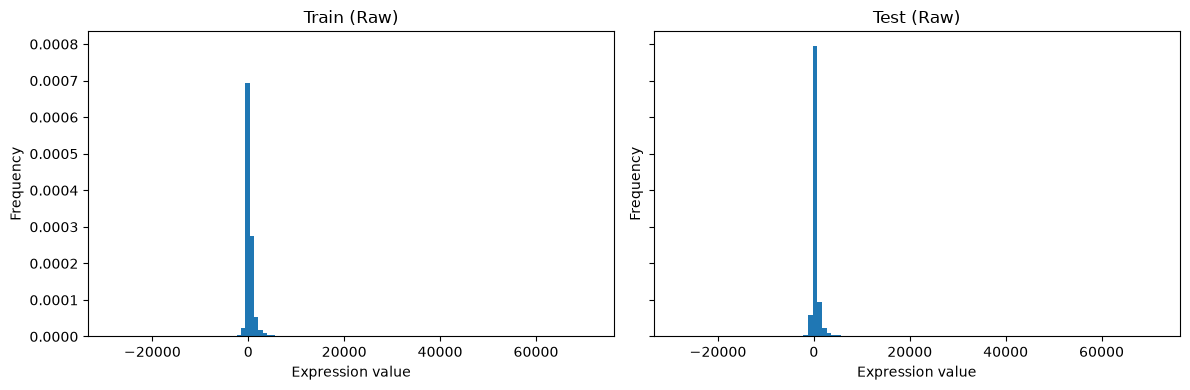

In [27]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)

for ax, data, title in zip(
    axes,
    [X_train, X_test],
    ["Train (Raw)", "Test (Raw)"]
):
    ax.hist(data.to_numpy().ravel(), bins=100, density = True)
    ax.set_title(title)
    ax.set_xlabel("Expression value")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

## 6. Expression Clipping and Log2 Transformation

In [91]:
# Clip expression values
X_train_clipped = X_train.clip(lower=20, upper=16000)
X_test_clipped = X_test.clip(lower=20, upper=16000)

# Log2 transformation
X_train_log2 = np.log2(X_train_clipped)
X_test_log2 = np.log2(X_test_clipped)

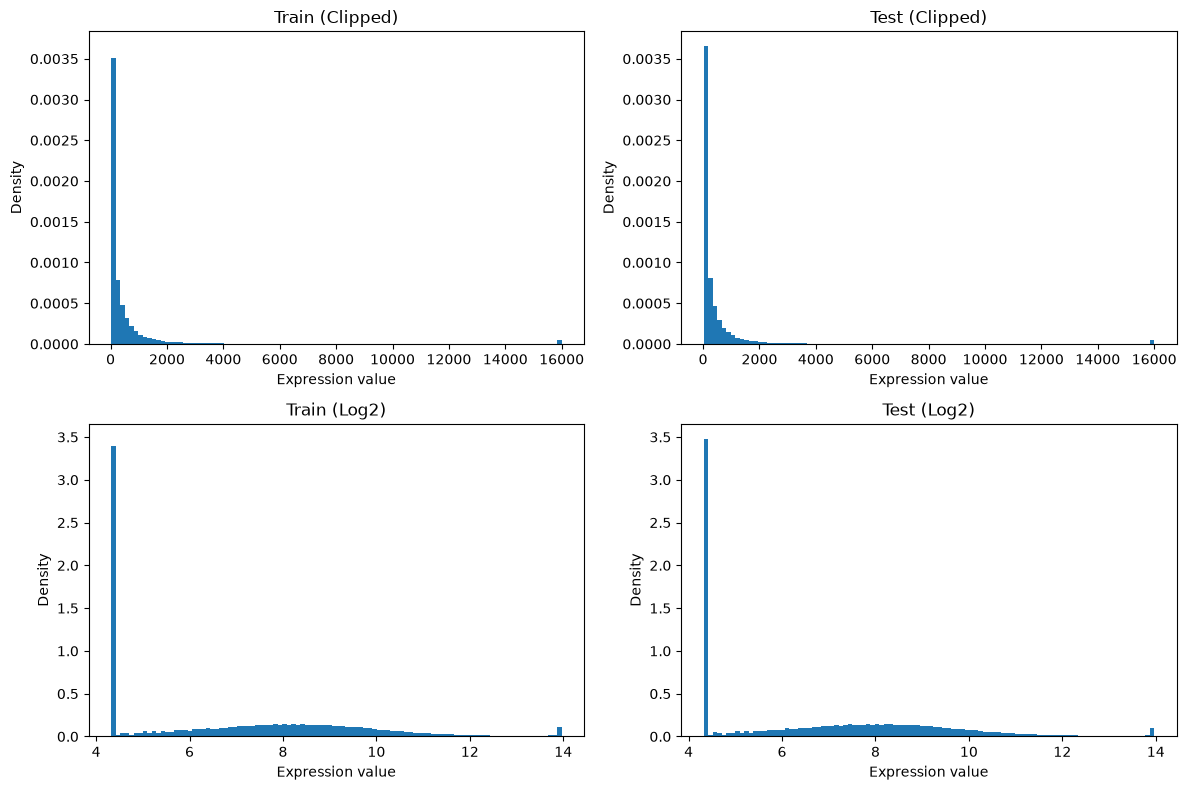

In [92]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

datasets = [
    [X_train_clipped, X_test_clipped],
    [X_train_log2, X_test_log2]
]

titles = [
    ["Train (Clipped)", "Test (Clipped)"],
    ["Train (Log2)", "Test (Log2)"]
]

for i in range(2):
    for j in range(2):
        ax = axes[i, j]
        ax.hist(datasets[i][j].to_numpy().ravel(),
                bins=100, density=True)
        ax.set_title(titles[i][j])
        ax.set_xlabel("Expression value")
        ax.set_ylabel("Density")

# Same axes within each transformation for train/test comparison
for row in axes:
    row[0].sharex(row[1])
    row[0].sharey(row[1])

plt.tight_layout()
plt.show()


## 7. Patient-Level and Class-Specific Expression Distributions

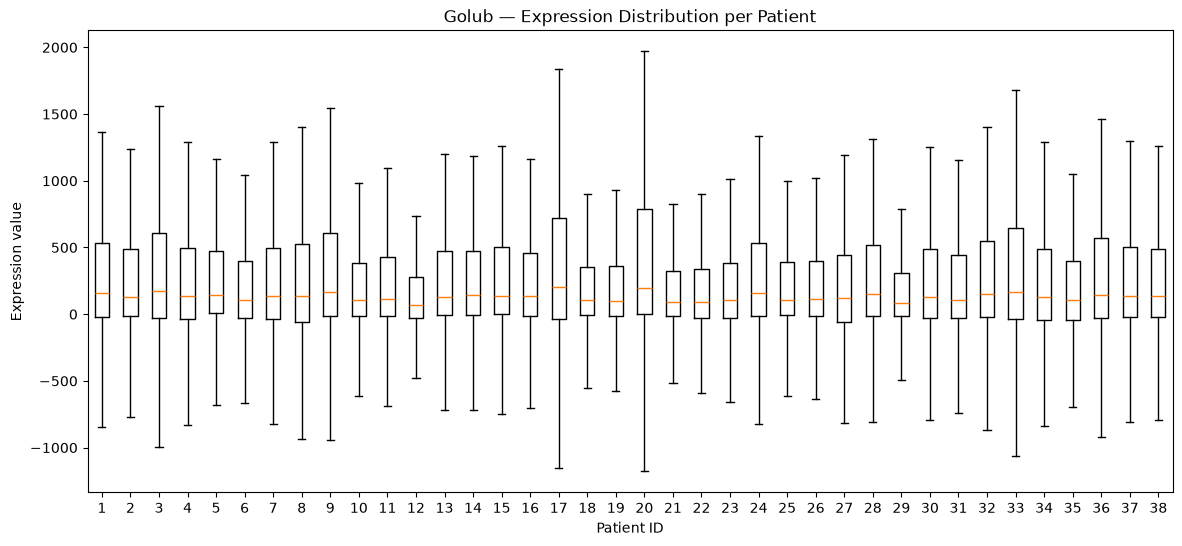

In [30]:
plt.figure(figsize=(14, 6))
plt.boxplot(X_train.T, showfliers=False)
plt.xlabel("Patient ID")
plt.ylabel("Expression value")
plt.title("Golub — Expression Distribution per Patient")
plt.show()

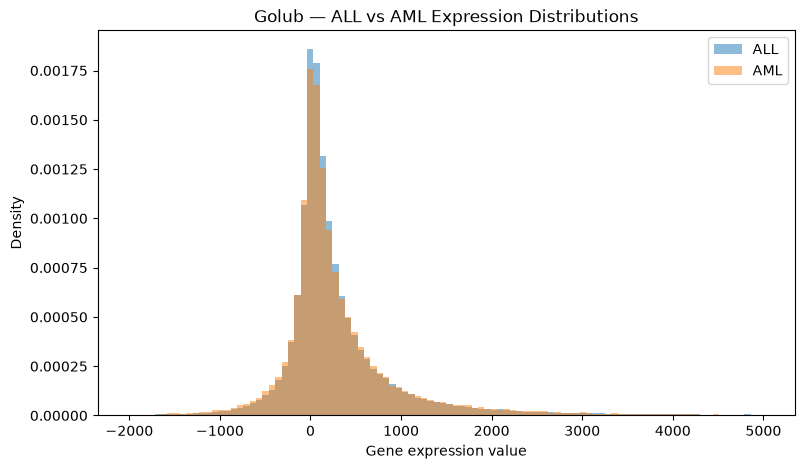

In [31]:
all_values = X_train.loc[train_expr["target"] == 1].to_numpy().flatten()
aml_values = X_train.loc[train_expr["target"] == 0].to_numpy().flatten()

plt.figure(figsize=(9, 5))

plt.hist(all_values, bins=100, range=(-2000, 5000),
         alpha=0.5, density=True, label="ALL")

plt.hist(aml_values, bins=100, range=(-2000, 5000),
         alpha=0.5, density=True, label="AML")

plt.xlabel("Gene expression value")
plt.ylabel("Density")
plt.title("Golub — ALL vs AML Expression Distributions")
plt.legend()
plt.show()

## 8. Gene-Wise Variability

In [32]:
gene_variances = X_train.var(axis=0)

print(gene_variances.describe())
print(gene_variances.nlargest(10))

count    7.129000e+03
mean     6.820928e+05
std      3.845060e+06
min      4.769018e+02
25%      8.210373e+03
50%      3.170128e+04
75%      1.295735e+05
max      1.609285e+08
dtype: float64
5709    1.609285e+08
5647    9.014333e+07
5506    6.822979e+07
6605    6.455910e+07
5710    6.425958e+07
18      5.694293e+07
5715    5.456498e+07
4016    4.963480e+07
5228    4.168747e+07
41      4.010845e+07
dtype: float64


## 9. Comparison of Expression Transformations

In [93]:
X_train_log = np.sign(X_train) * np.log2(1 + np.abs(X_train))
X_train_asinh = np.arcsinh(X_train)

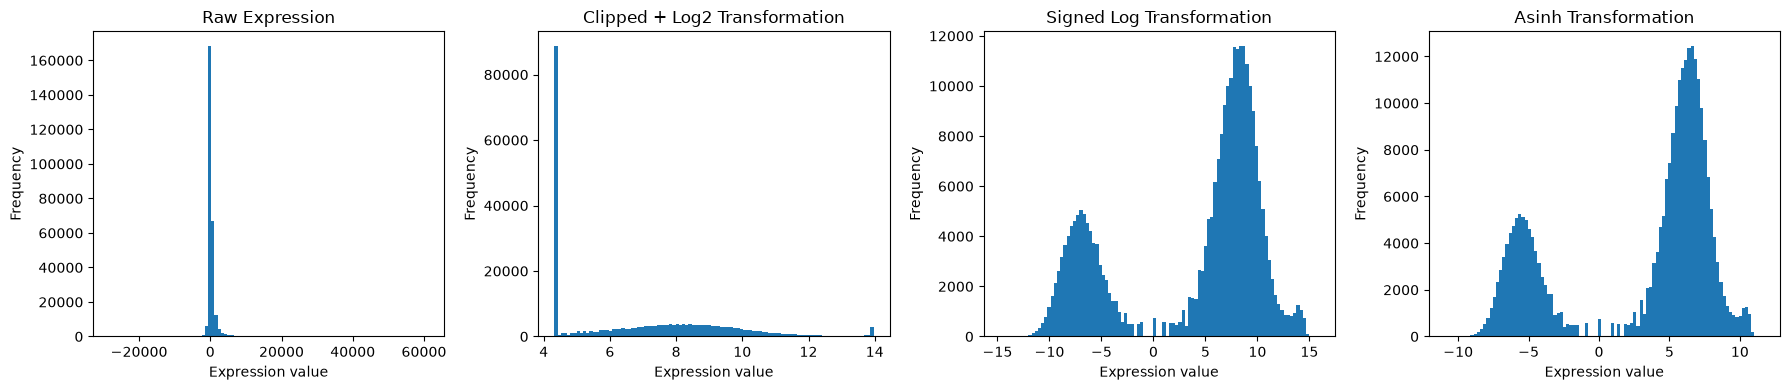

In [95]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

datasets = [
    (X_train, "Raw Expression"),
    (X_train_log2, "Clipped + Log2 Transformation"),
    (X_train_log, "Signed Log Transformation"),
    (X_train_asinh, "Asinh Transformation"),
    
]

for ax, (data, title) in zip(axes, datasets):
    ax.hist(data.to_numpy().ravel(), bins=100)
    ax.set_title(title)
    ax.set_xlabel("Expression value")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

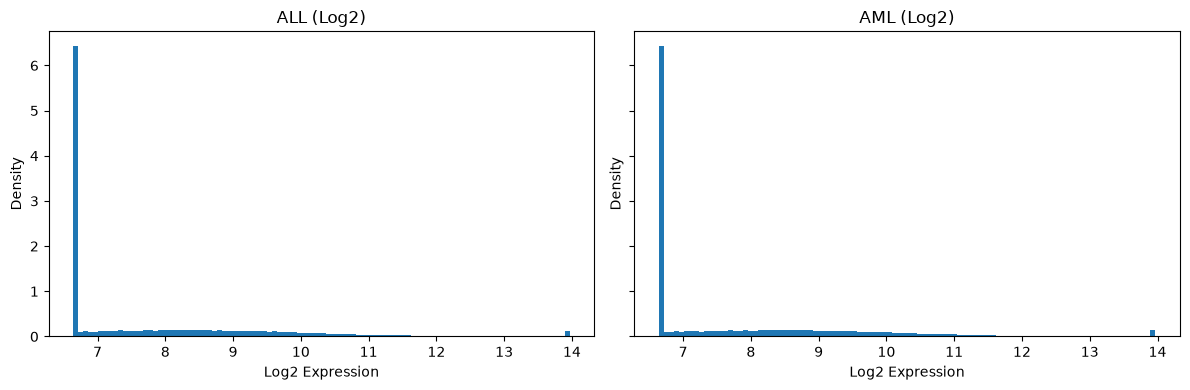

In [35]:
all_log2 = X_train_log2.loc[train_expr["target"] == 1]
aml_log2 = X_train_log2.loc[train_expr["target"] == 0]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)

for ax, data, title in zip(
    axes,
    [all_log2, aml_log2],
    ["ALL (Log2)", "AML (Log2)"]
):
    ax.hist(data.to_numpy().ravel(), bins=100, density=True)
    ax.set_title(title)
    ax.set_xlabel("Log2 Expression")
    ax.set_ylabel("Density")

plt.tight_layout()
plt.show()

## 10. Principal Component Analysis (PCA)

### Standardization, Projection, Explained Variance, and Loadings

In [36]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train_log2)

In [37]:
from sklearn.decomposition import PCA

pca = PCA()
X_pca = pca.fit_transform(X_scaled)

pc1_loadings = pd.Series(pca.components_[0], index=X_train.columns)

In [38]:
print(X_pca.shape)
cumsum = np.cumsum(pca.explained_variance_ratio_)

(38, 38)


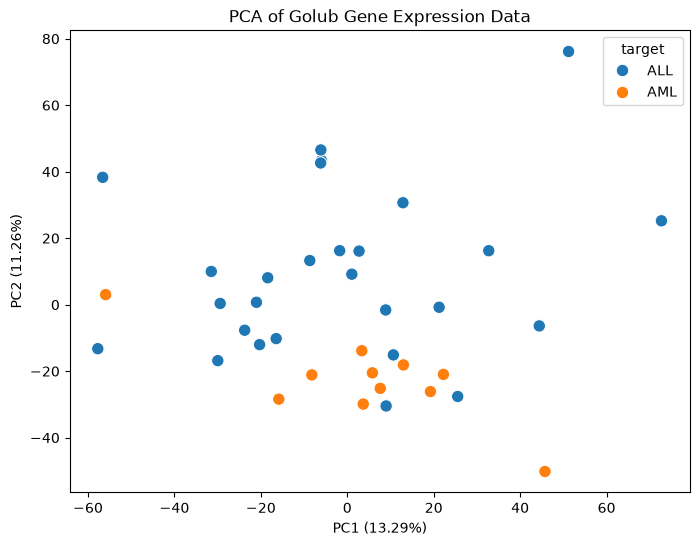

In [39]:
import seaborn as sns
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=train_expr["target"].map({1: "ALL", 0: "AML"}),
    s=80
)

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.2%})")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.2%})")
plt.title("PCA of Golub Gene Expression Data")
plt.show()

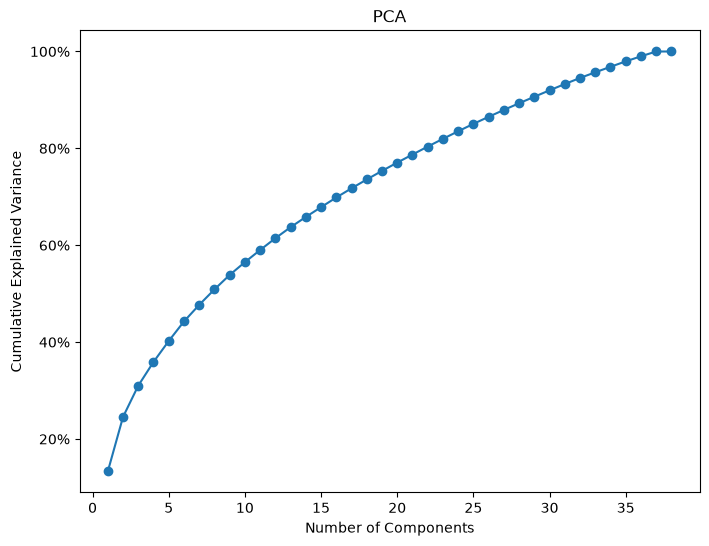

In [40]:
from matplotlib.ticker import PercentFormatter

line_plot = plt.figure(figsize=(8, 6))
plt.plot(np.arange(1, len(cumsum) + 1), cumsum, marker="o")
plt.gca().yaxis.set_major_formatter(PercentFormatter(1.0))
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA")
plt.show()

In [42]:
pc1_loadings.loc[pc1_loadings.abs().nlargest(10).index]

5833    0.031184
7012    0.030750
5995    0.030740
430     0.030363
5438    0.030081
3835    0.029936
4738    0.029902
3439    0.029875
3222    0.029873
3754    0.029610
dtype: float64

## 11. UMAP Visualization

In [43]:
from umap import UMAP

In [44]:
import umap

In [45]:
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=SEED)
X_umap = reducer.fit_transform(X_scaled)

c:\Users\zehra\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


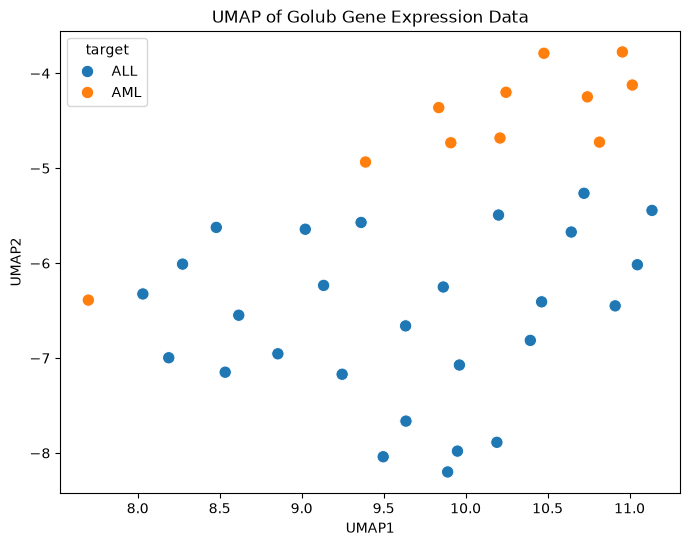

In [46]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=X_umap[:, 0],
    y=X_umap[:, 1],
    hue=train_expr["target"].map({1: "ALL", 0: "AML"}),
    s=80
)

plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
plt.title("UMAP of Golub Gene Expression Data")
plt.show()

## 12. Differential Expression and Hierarchical Clustering

### Welch’s t-tests and FDR Correction

In [103]:

import numpy as np
import pandas as pd
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

# 1. Exclude target column
X_expr = X_train_log2.drop(columns="target", errors="ignore")

# 2. Exclude constant and near-constant probes
valid_mask = (
    (X_expr.nunique(axis=0) > 1) &
    (X_expr.std(axis=0) > 1e-8)
)

valid_probes = X_expr.columns[valid_mask]

# 3. Separate ALL and AML samples
all_data = X_expr.loc[
    train_expr["target"] == 1, valid_probes
]

aml_data = X_expr.loc[
    train_expr["target"] == 0, valid_probes
]

# 4. Welch's t-test
t_stat, p_value = ttest_ind(
    all_data,
    aml_data,
    axis=0,
    equal_var=False
)

# 5. Exclude any remaining invalid tests
finite_mask = np.isfinite(p_value) & np.isfinite(t_stat)

valid_probes = valid_probes[finite_mask]
t_stat = t_stat[finite_mask]
p_value = p_value[finite_mask]

all_data = all_data.loc[:, valid_probes]
aml_data = aml_data.loc[:, valid_probes]

# 6. Benjamini-Hochberg FDR correction
rejected, pvals_corrected, _, _ = multipletests(
    p_value,
    alpha=0.05,
    method="fdr_bh"
)

# 7. Summary
print("Total probes:", X_expr.shape[1])
print("Valid probes tested:", len(p_value))
print("Significant probes (FDR < 0.05):", rejected.sum())

# 8. Probe-level statistics
golub_gene_stats = pd.DataFrame({
    "probe": train.loc[valid_probes, "Gene Accession Number"].values,
    "t_stat": t_stat,
    "p_value": p_value,
    "p_adjusted": pvals_corrected,
    "mean_difference": (
        all_data.mean().values - aml_data.mean().values
    )
}, index=valid_probes)

# 9. Rank probes by adjusted p-value
golub_gene_stats = golub_gene_stats.sort_values("p_adjusted")

display(golub_gene_stats.head(20))

# 10. Select top 20 and top 50 probes
ranked_probes = golub_gene_stats.index

X_top20 = X_expr.loc[:, ranked_probes[:20]].copy()
X_top50 = X_expr.loc[:, ranked_probes[:50]].copy()

# 11. Final checks
print("Top 20 shape:", X_top20.shape)
print("Top 50 shape:", X_top50.shape)
print("Minimum std (Top 20):", X_top20.std().min())
print("Minimum std (Top 50):", X_top50.std().min())


Total probes: 7129
Valid probes tested: 6638
Significant probes (FDR < 0.05): 604


c:\Users\zehra\AppData\Local\Programs\Python\Python313\Lib\site-packages\scipy\stats\_axis_nan_policy.py:644: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, axis=axis, **kwds)


,probe,t_stat,p_value,p_adjusted,mean_difference
1881,M27891_at,-9.532188,4.392536e-10,0.000003,-5.916760
4846,X95735_at,-8.114032,1.222489e-09,0.000004,-3.595993
2019,M55150_at,-7.740882,3.984953e-09,0.000009,-1.310712
6973,M28170_at,7.391172,1.107731e-08,0.000018,2.625265
4229,X52142_at,8.050984,1.569946e-08,0.000021,2.372917
5038,Y12670_at,-7.696738,3.497184e-08,0.000037,-1.753139
3319,U50136_rna1_at,-8.480939,4.972638e-08,0.000037,-1.402700
6854,M31523_at,7.473562,4.986710e-08,0.000037,1.950013
2266,M81933_at,-6.891411,4.594229e-08,0.000037,-1.764919
2758,U12471_cds1_at,-6.675747,9.039435e-08,0.000060,-1.027221


Top 20 shape: (38, 20)
Top 50 shape: (38, 50)
Minimum std (Top 20): 0.7440215942050604
Minimum std (Top 50): 0.7440215942050604


### Clustered Heatmaps of the Top 20 and Top 50 Probes

In [108]:
class_labels = train_expr.loc[X_top20.index, "target"].map({
    1: "ALL",
    0: "AML"
}).rename("Class")

class_colors = class_labels.map({
    "ALL": "steelblue",
    "AML": "darkorange"
})


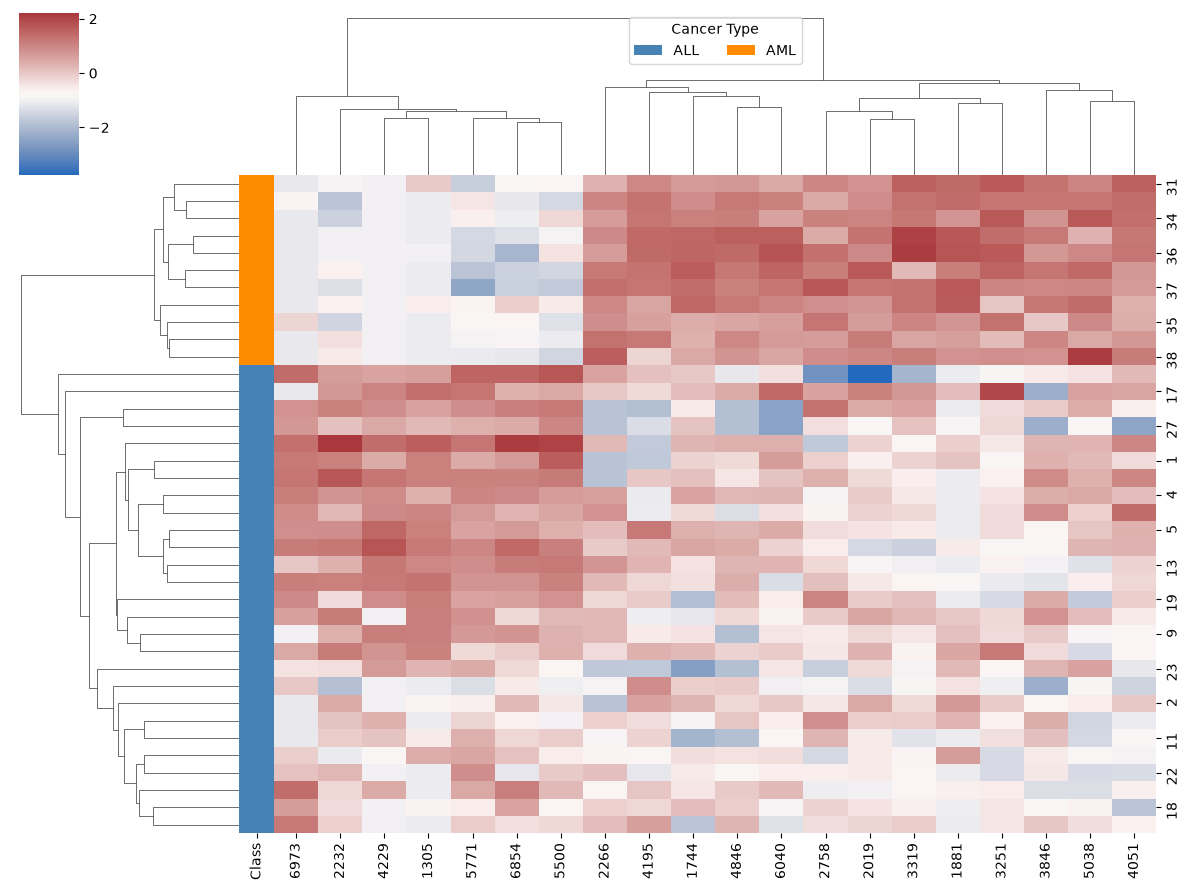

In [109]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

g20 = sns.clustermap(
    X_top20,
    z_score=1,
    cmap="vlag",
    method="average",
    metric="euclidean",
    row_colors=class_colors,
    figsize=(12, 9))
g20.ax_heatmap.legend(
    handles=[
        Patch(facecolor="steelblue", label="ALL"),
        Patch(facecolor="darkorange", label="AML")
    ],
    title="Cancer Type",
    loc="upper center",
    bbox_to_anchor=(0.5, 1.25),
    ncol=2
)
plt.show()

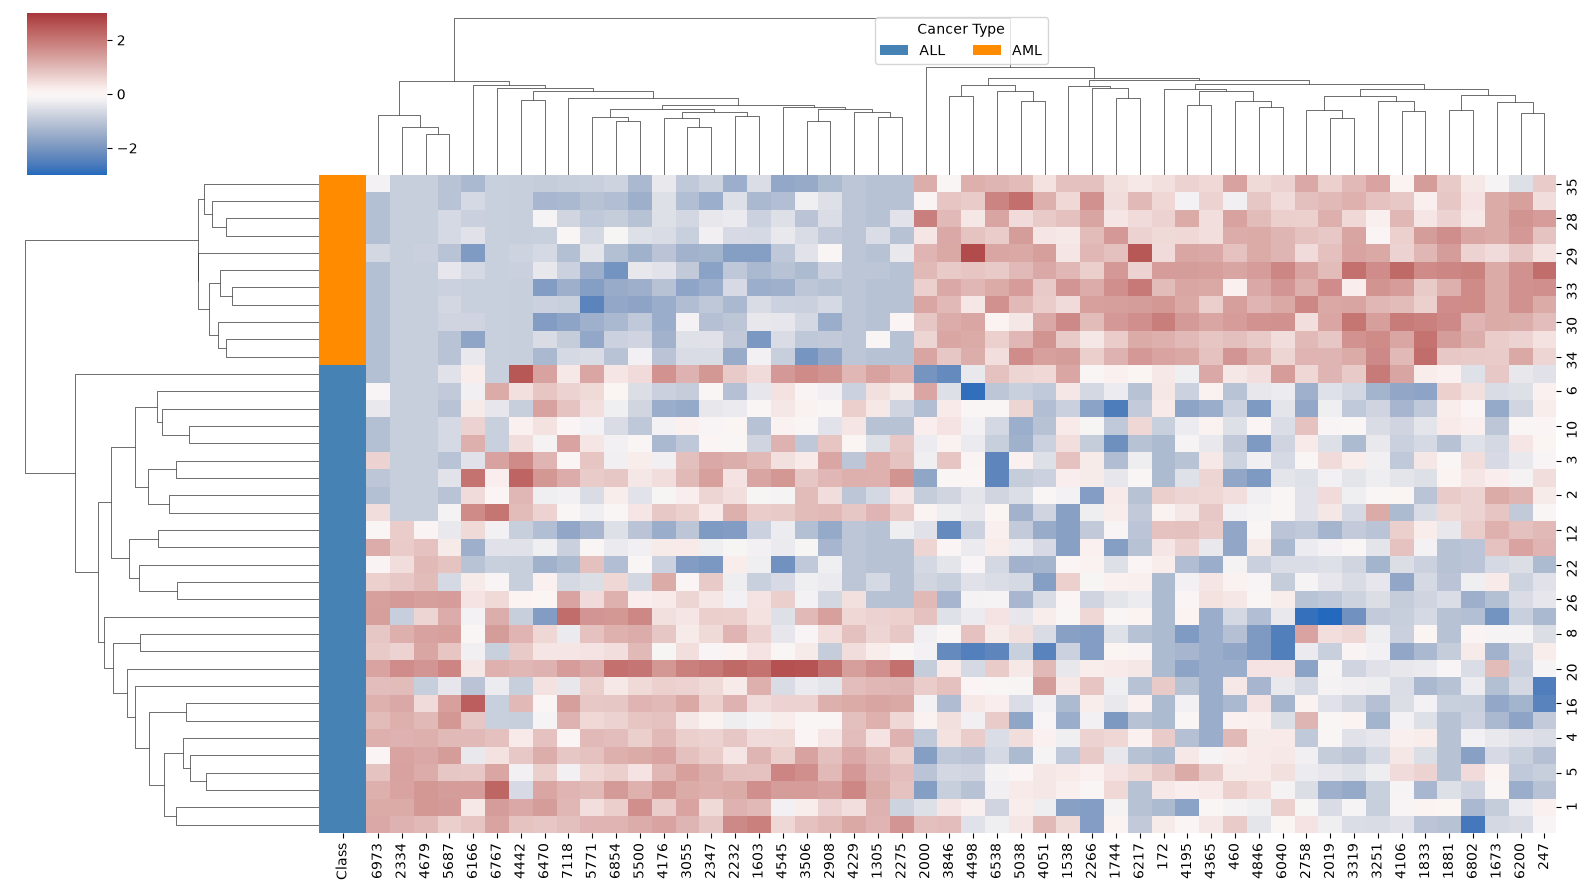

In [110]:
g50 = sns.clustermap(
    X_top50,
    z_score=1,
    cmap="vlag",
    method="average",
    metric="euclidean",
    figsize=(16, 9),
    row_colors=class_colors,
    xticklabels=True,
    center=0,
    vmin=-3,
    vmax=3
)

g50.ax_heatmap.legend(
    handles=[
        Patch(facecolor="steelblue", label="ALL"),
        Patch(facecolor="darkorange", label="AML")
    ],
    title="Cancer Type",
    loc="upper center",
    bbox_to_anchor=(0.5, 1.25),
    ncol=2
)

plt.show()

## 13. Training vs. Independent Test: Distribution Differences and Potential Batch Effects

### Feature Alignment and Descriptive Statistics

In [51]:
X_test = test_expr.drop(columns=["target"])

In [52]:
print(X_test.shape)
print(X_train.shape)
print(X_test.columns.equals(X_train.columns))

(34, 7129)
(38, 7129)
True


In [53]:
print("Training:")
print(X_train.stack().describe())

print("\nIndependent test:")
print(X_test.stack().describe())

Training:
count    270902.000000
mean        637.698001
std        2426.222638
min      -28400.000000
25%         -20.000000
50%         127.000000
75%         466.000000
max       61228.000000
dtype: float64

Independent test:
count    242386.000000
mean        599.751269
std        2459.492368
min      -26775.000000
25%         -21.000000
50%         114.000000
75%         410.000000
max       71369.000000
dtype: float64


### Gene-Wise Mean Expression Shifts

In [54]:
train_gene_means = X_train_log2.mean(axis=0)
test_gene_means = X_test_log2.mean(axis=0)

mean_shifts = (test_gene_means - train_gene_means).abs()

print(mean_shifts.describe())
print("Median absolute gene-wise shift:", mean_shifts.median())

count    7129.000000
mean        0.166988
std         0.193237
min         0.000000
25%         0.023388
50%         0.102590
75%         0.256088
max         2.493928
dtype: float64
Median absolute gene-wise shift: 0.10258976286883037


### Overall Training and Test Expression Distributions

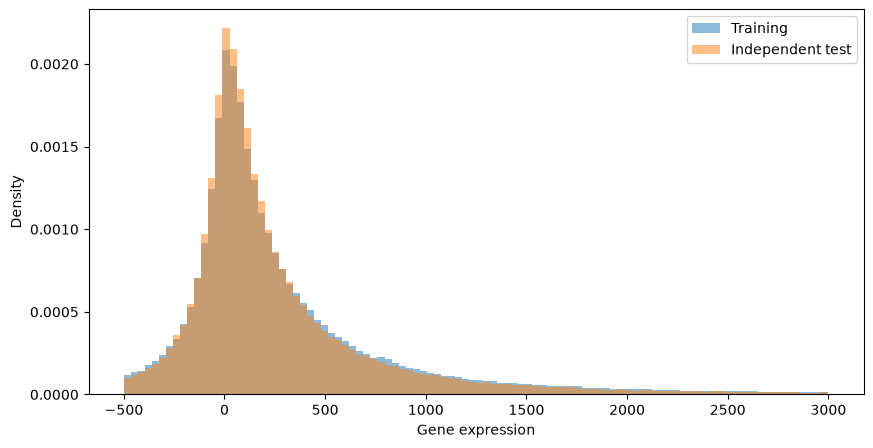

In [55]:
train_values = X_train.to_numpy().ravel()
test_values = X_test.to_numpy().ravel()

plt.figure(figsize=(10, 5))

plt.hist(train_values, bins=100, range=(-500, 3000),
         density=True, alpha=0.5, label="Training")

plt.hist(test_values, bins=100, range=(-500, 3000),
         density=True, alpha=0.5, label="Independent test")

plt.xlabel("Gene expression")
plt.ylabel("Density")
plt.legend()
plt.show()

### Training and Test Distributions Within Each Diagnosis

In [56]:
train_all = train_expr.loc[train_expr["target"] == 1].drop(columns="target")
test_all = test_expr.loc[test_expr["target"] == 1].drop(columns="target")

train_aml = train_expr.loc[train_expr["target"] == 0].drop(columns="target")
test_aml = test_expr.loc[test_expr["target"] == 0].drop(columns="target")

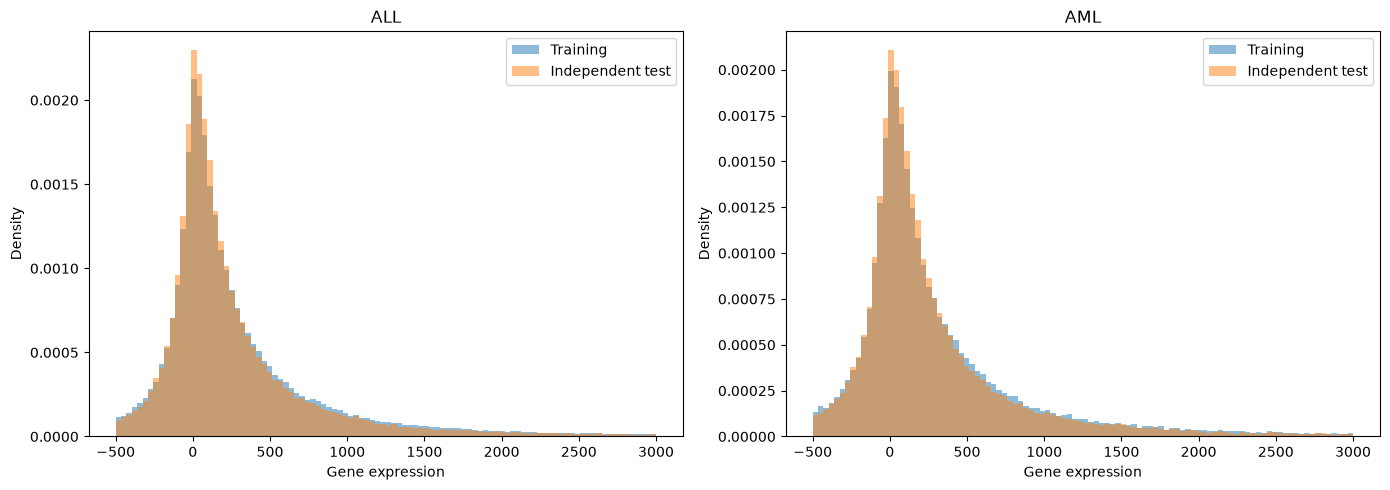

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, train_subset, test_subset, title in zip(
    axes,
    [train_all, train_aml],
    [test_all, test_aml],
    ["ALL", "AML"]
):
    ax.hist(train_subset.to_numpy().ravel(), bins=100, range=(-500, 3000),
            density=True, alpha=0.5, label="Training")
    ax.hist(test_subset.to_numpy().ravel(), bins=100, range=(-500, 3000),
            density=True, alpha=0.5, label="Independent test")

    ax.set_title(title)
    ax.set_xlabel("Gene expression")
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()

### PCA Comparison of Training and Independent Test Patients

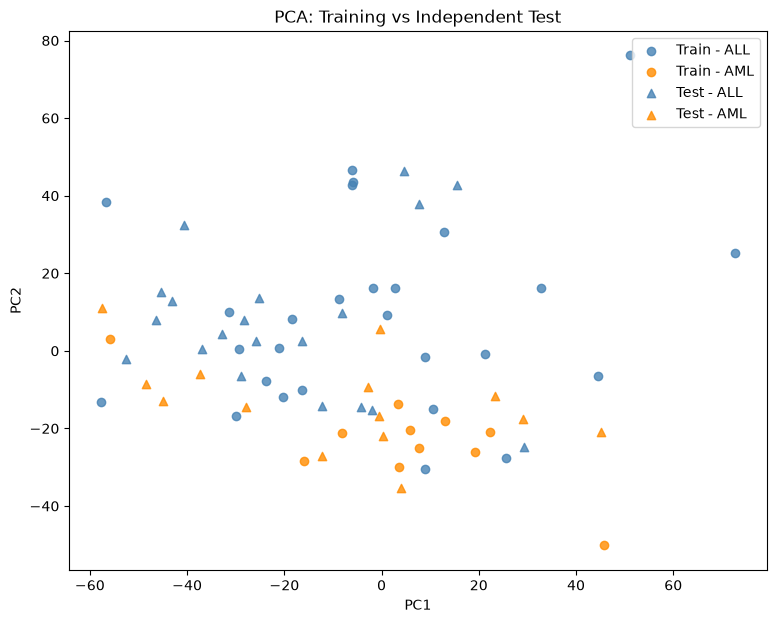

In [58]:
X_train_pca = X_pca
X_test_pca = pca.transform(scaler.transform(X_test_log2))

fig, ax = plt.subplots(figsize=(9, 7))

for pca_coords, labels, marker, dataset in [
    (X_train_pca, train_expr["target"], "o", "Train"),
    (X_test_pca, test_expr["target"], "^", "Test")
]:
    for target, color, cancer in [
        (1, "steelblue", "ALL"),
        (0, "darkorange", "AML")
    ]:
        mask = labels.to_numpy() == target

        ax.scatter(
            pca_coords[mask, 0],
            pca_coords[mask, 1],
            c=color,
            marker=marker,
            alpha=0.8,
            label=f"{dataset} - {cancer}"
        )

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("PCA: Training vs Independent Test")
ax.legend()
plt.show()

# Shipp Dataset: Exploratory Data Analysis (DLBCL vs. FL)

## 1. Dataset Loading and Initial Inspection

In [59]:
url = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE68nnn/GSE68895/matrix/GSE68895_series_matrix.txt.gz"

shipp_raw = pd.read_csv(
    url,
    sep="\t",
    comment="!",
    index_col=0
)

print(shipp_raw.shape)
print(shipp_raw.iloc[:5, :5])

(7129, 77)
               GSM1685734  GSM1685735  GSM1685736  GSM1685737  GSM1685738
ID_REF                                                                   
A28102_at           151.3       504.6       234.7       375.7       137.8
AB000114_at          20.6        70.2       176.8       151.4        13.8
AB000115_at         248.1       385.1       901.5       390.6       337.0
AB000220_at          73.7       312.6       133.9       246.9       330.1
AB000381_s_at        25.2        29.0        39.4         6.0         8.9


## 2. Expression Matrix Preparation and Diagnosis Labels

In [60]:
shipp_expr = shipp_raw.T

print(shipp_expr.shape)
print(shipp_expr.iloc[:3, :5])

(77, 7129)
ID_REF      A28102_at  AB000114_at  AB000115_at  AB000220_at  AB000381_s_at
GSM1685734      151.3         20.6        248.1         73.7           25.2
GSM1685735      504.6         70.2        385.1        312.6           29.0
GSM1685736      234.7        176.8        901.5        133.9           39.4


In [61]:
import gzip
import urllib.request

with urllib.request.urlopen(url) as response:
    with gzip.open(response, "rt") as f:
        for line in f:
            if line.startswith("!Sample_characteristics_ch1"):
                print(line[:500])

!Sample_characteristics_ch1	"disease state: Diffuse large B-cell Lymphoma"	"disease state: Diffuse large B-cell Lymphoma"	"disease state: Diffuse large B-cell Lymphoma"	"disease state: Diffuse large B-cell Lymphoma"	"disease state: Diffuse large B-cell Lymphoma"	"disease state: Diffuse large B-cell Lymphoma"	"disease state: Diffuse large B-cell Lymphoma"	"disease state: Diffuse large B-cell Lymphoma"	"disease state: Diffuse large B-cell Lymphoma"	"disease state: Diffuse large B-cell Lymphoma"	"d
!Sample_characteristics_ch1	"cell type: B-Lymphocyte"	"cell type: B-Lymphocyte"	"cell type: B-Lymphocyte"	"cell type: B-Lymphocyte"	"cell type: B-Lymphocyte"	"cell type: B-Lymphocyte"	"cell type: B-Lymphocyte"	"cell type: B-Lymphocyte"	"cell type: B-Lymphocyte"	"cell type: B-Lymphocyte"	"cell type: B-Lymphocyte"	"cell type: B-Lymphocyte"	"cell type: B-Lymphocyte"	"cell type: B-Lymphocyte"	"cell type: B-Lymphocyte"	"cell type: B-Lymphocyte"	"cell type: B-Lymphocyte"	"cell type: B-Lymphocyte"	"ce

In [62]:
import csv

with urllib.request.urlopen(url) as response:
    with gzip.open(response, "rt") as f:
        for line in f:
            if line.startswith("!Sample_characteristics_ch1"):
                values = next(csv.reader([line], delimiter="\t"))[1:]

                if all(v.startswith("disease state:") for v in values):
                    diagnoses = [v.split(":", 1)[1].strip() for v in values]
                    break

print(pd.Series(diagnoses).value_counts())

Diffuse large B-cell Lymphoma    58
Follicular Lymphoma              19
Name: count, dtype: int64


In [63]:
shipp_expr["target"] = [
    1 if diagnosis == "Diffuse large B-cell Lymphoma" else 0
    for diagnosis in diagnoses
]

In [64]:
print(shipp_expr.shape)
print(shipp_expr["target"].value_counts())
print(shipp_expr.iloc[:3, -3:])

(77, 7130)
target
1    58
0    19
Name: count, dtype: int64
ID_REF      Z97054_xpt2_at  Z97074_at  target
GSM1685734           372.7      139.8       1
GSM1685735            90.4      142.6       1
GSM1685736           431.4      117.7       1


Text(0.5, 1.0, 'Shipp — Expression Distribution per Feature')

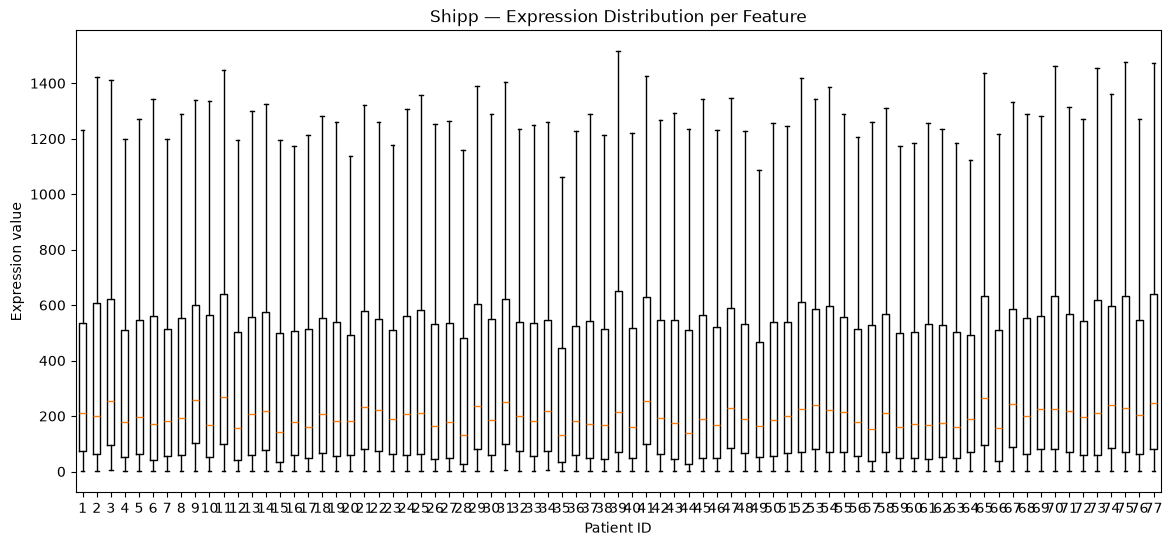

In [65]:
plt.figure(figsize=(14, 6))
plt.boxplot(shipp_expr.drop(columns="target").T, showfliers=False)
plt.xlabel("Patient ID")
plt.ylabel("Expression value")
plt.title("Shipp — Expression Distribution per Feature")

## 3. Stratified 80/20 Training and Held-Out Test Split

Training: (61, 7129)
Held-out test: (16, 7129)


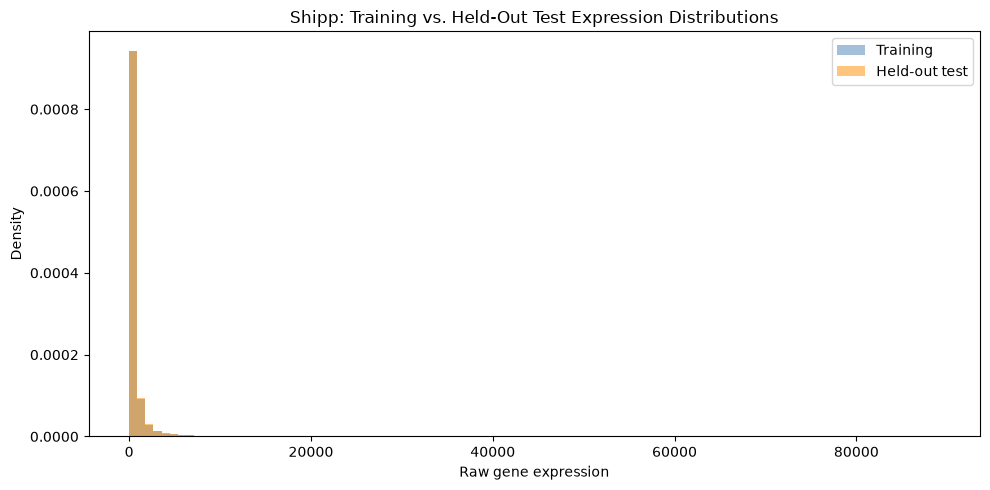

In [66]:
from sklearn.model_selection import train_test_split

X_shipp = shipp_expr.drop(columns="target")
y_shipp = shipp_expr["target"].copy()
X_shipp_train, X_shipp_test, y_shipp_train, y_shipp_test = train_test_split(
    X_shipp, y_shipp, test_size=0.20, stratify=y_shipp, random_state=SEED
)
# Sort for stable display while preserving feature/label alignment.
X_shipp_train = X_shipp_train.sort_index()
X_shipp_test = X_shipp_test.sort_index()
y_shipp_train = y_shipp_train.loc[X_shipp_train.index]
y_shipp_test = y_shipp_test.loc[X_shipp_test.index]
assert X_shipp_train.index.intersection(X_shipp_test.index).empty
assert X_shipp_train.columns.equals(X_shipp_test.columns)
print("Training:", X_shipp_train.shape)
print("Held-out test:", X_shipp_test.shape)

# Compare pooled gene expression distributions using shared histogram bins.
shipp_train_values = X_shipp_train.to_numpy().ravel()
shipp_test_values = X_shipp_test.to_numpy().ravel()
shipp_split_bins = np.histogram_bin_edges(
    np.concatenate([shipp_train_values, shipp_test_values]), bins=100
)
fig, ax = plt.subplots(figsize=(10, 5))
for values, label, color in [
    (shipp_train_values, "Training", "steelblue"),
    (shipp_test_values, "Held-out test", "darkorange")
]:
    ax.hist(values, bins=shipp_split_bins, density=True,
            alpha=0.5, color=color, label=label)
ax.set_title("Shipp: Training vs. Held-Out Test Expression Distributions")
ax.set_xlabel("Raw gene expression")
ax.set_ylabel("Density")
ax.legend()
plt.tight_layout()
plt.show()


## 4. Probe Overlap and Alignment Between Golub and Shipp

In [67]:
golub_probes = set(train["Gene Accession Number"].dropna())
shipp_probes = set(shipp_expr.drop(columns="target").columns)
common_probes = golub_probes & shipp_probes
print("Golub probes:", len(golub_probes))
print("Shipp probes:", len(shipp_probes))
print("Common probes:", len(common_probes))

Golub probes: 7129
Shipp probes: 7129
Common probes: 7129


In [68]:
print(train["Gene Accession Number"].duplicated().sum())
print(shipp_expr.columns.duplicated().sum())

0
0


In [69]:
golub_train = train.set_index("Gene Accession Number")
golub_test = test.set_index("Gene Accession Number")

In [70]:
print(golub_train.columns[:8].tolist())
print(golub_test.columns[:8].tolist())

['Gene Description', '1', 'call', '2', 'call.1', '3', 'call.2', '4']
['Gene Description', '39', 'call', '40', 'call.1', '42', 'call.2', '47']


In [71]:
# Keep diagnosis labels in shipp_expr; use a separate expression-only matrix.
shipp_features = shipp_expr.drop(columns="target")

In [72]:
golub_train_expr = golub_train.loc[
    :, golub_train.columns.str.isdigit()
].T

golub_test_expr = golub_test.loc[
    :, golub_test.columns.str.isdigit()
].T

golub_all = pd.concat([golub_train_expr, golub_test_expr])

In [73]:
golub_aligned = golub_all.loc[:, shipp_features.columns]
shipp_aligned = shipp_features.loc[:, golub_aligned.columns]
print(golub_aligned.shape)
print(shipp_aligned.shape)
print(golub_aligned.columns.equals(shipp_aligned.columns))

(72, 7129)
(77, 7129)
True


## 5. Exact Expression Profile Overlap Between Golub and Shipp

In [74]:
matches = []

for golub_id, golub_row in golub_aligned.iterrows():
    for shipp_id, shipp_row in shipp_aligned.iterrows():
        if np.array_equal(golub_row.to_numpy(), shipp_row.to_numpy()):
            matches.append((golub_id, shipp_id))

print("Identical patient profiles:", matches)
print("Number of matches:", len(matches))

Identical patient profiles: []
Number of matches: 0


## 6. Data Quality Checks

In [75]:
for name, X in [("Training", X_shipp_train), ("Held-out test", X_shipp_test)]:
    print(f"\n{name}: {X.shape}")
    print("Missing values:", X.isna().sum().sum())
    print("Infinite values:", np.isinf(X.to_numpy()).sum())
    print("Negative values:", (X < 0).sum().sum())
    print("Zero values:", (X == 0).sum().sum())
    print("Duplicate samples:", X.duplicated().sum())
    print("Constant probes:", (X.nunique() <= 1).sum())


Training: (61, 7129)
Missing values: 0
Infinite values: 0
Negative values: 0
Zero values: 0
Duplicate samples: 0
Constant probes: 0

Held-out test: (16, 7129)
Missing values: 0
Infinite values: 0
Negative values: 0
Zero values: 0
Duplicate samples: 0
Constant probes: 0


## 7. Descriptive Statistics and Raw Expression Distributions

In [76]:
shipp_summary = pd.DataFrame({
    name: pd.Series(X.to_numpy().ravel()).describe(percentiles=[0.25, 0.5, 0.75, 0.99, 0.999])
    for name, X in [("Training", X_shipp_train), ("Held-out test", X_shipp_test)]
})
display(shipp_summary)

,Training,Held-out test
count,434869.000000,114064.000000
mean,833.558014,864.637006
std,2875.362264,3133.125443
min,0.100000,0.300000
25%,59.800000,66.100000
50%,195.300000,205.600000
75%,552.600000,564.000000
99%,15207.180000,16512.702000
99.9%,35500.762000,40008.359600
max,89141.800000,80317.000000


## 8. Log2 Transformation

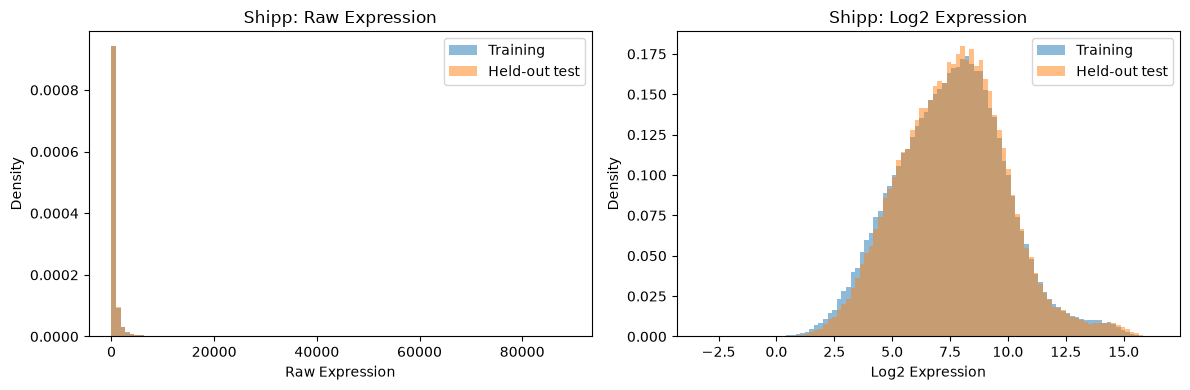

In [77]:
# Fixed transformation applied independently to each split.
assert (X_shipp_train > 0).all().all() and (X_shipp_test > 0).all().all()
X_shipp_train_log = np.log2(X_shipp_train)
X_shipp_test_log = np.log2(X_shipp_test)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, datasets, title in [
    (axes[0], [X_shipp_train, X_shipp_test], "Raw Expression"),
    (axes[1], [X_shipp_train_log, X_shipp_test_log], "Log2 Expression")
]:
    bins = np.linspace(min(X.min().min() for X in datasets), max(X.max().max() for X in datasets), 101)
    for X, label in zip(datasets, ["Training", "Held-out test"]):
        ax.hist(X.to_numpy().ravel(), bins=bins, density=True, alpha=0.5, label=label)
    ax.set(title=f"Shipp: {title}", xlabel=title, ylabel="Density")
    ax.legend()
plt.tight_layout()
plt.show()

## 9. Class-Specific Log2 Expression Distributions

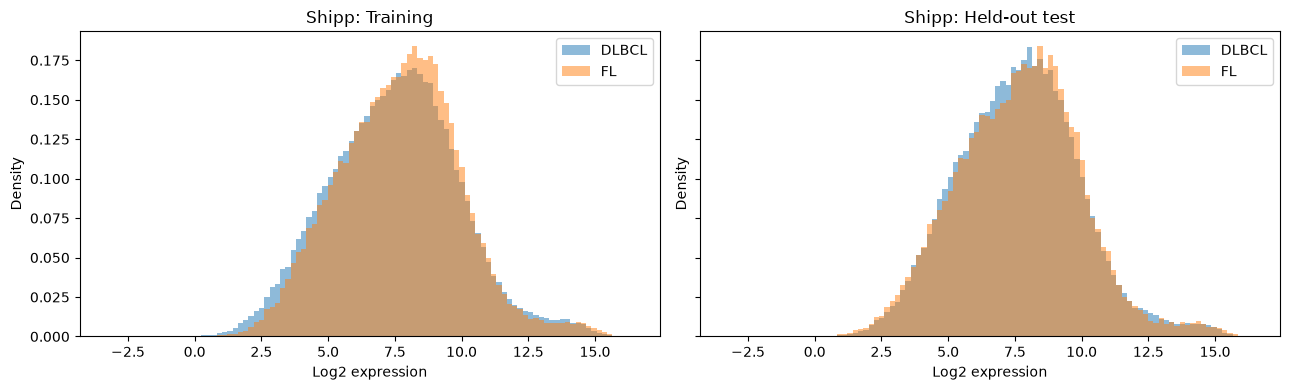

In [78]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharex=True, sharey=True)
shipp_log_bins = np.linspace(min(X_shipp_train_log.min().min(), X_shipp_test_log.min().min()),
                             max(X_shipp_train_log.max().max(), X_shipp_test_log.max().max()), 101)
for ax, X, y, split in zip(axes, [X_shipp_train_log, X_shipp_test_log],
                          [y_shipp_train, y_shipp_test], ["Training", "Held-out test"]):
    for target, label in [(1, "DLBCL"), (0, "FL")]:
        ax.hist(X.loc[y == target].to_numpy().ravel(), bins=shipp_log_bins,
                density=True, alpha=0.5, label=label)
    ax.set(title=f"Shipp: {split}", xlabel="Log2 expression", ylabel="Density")
    ax.legend()
plt.tight_layout()
plt.show()

## 10. Principal Component Analysis (PCA)

### Standardization and Explained Variance

In [79]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaler = StandardScaler()
X_shipp_train_scaled = scaler.fit_transform(X_shipp_train_log)
X_shipp_test_scaled = scaler.transform(X_shipp_test_log)
shipp_pca = PCA()
X_shipp_train_pca = shipp_pca.fit_transform(X_shipp_train_scaled)
X_shipp_test_pca = shipp_pca.transform(X_shipp_test_scaled)
print("Training PC1 explained variance:", shipp_pca.explained_variance_ratio_[0])
print("Training PC2 explained variance:", shipp_pca.explained_variance_ratio_[1])
print("Cumulative PC1 + PC2:", shipp_pca.explained_variance_ratio_[:2].sum())

Training PC1 explained variance: 0.22443910821149265
Training PC2 explained variance: 0.06968891200167736
Cumulative PC1 + PC2: 0.29412802021317


### PCA Visualization by Cancer Class

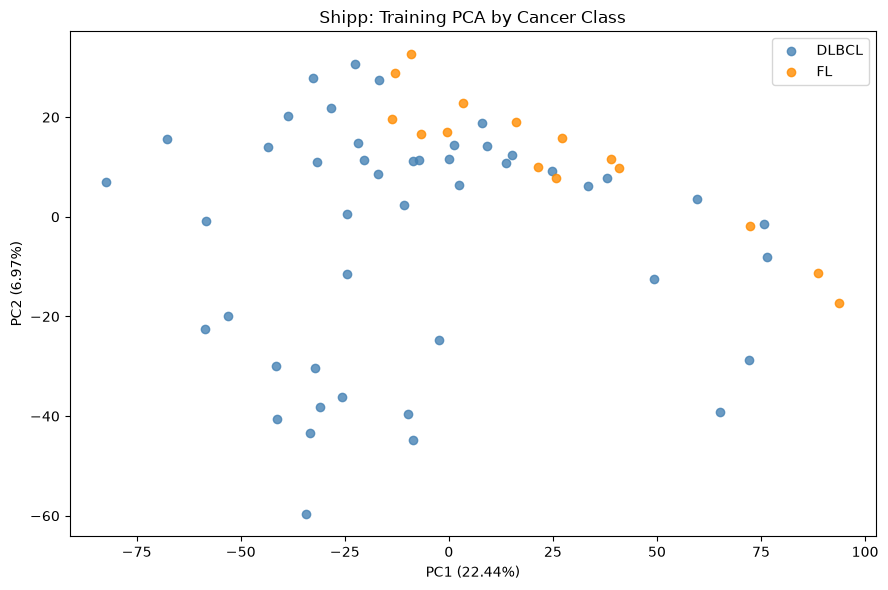

In [80]:
fig, ax = plt.subplots(figsize=(9, 6))
for target, label, color in [(1, "DLBCL", "steelblue"), (0, "FL", "darkorange")]:
    mask = y_shipp_train.to_numpy() == target
    ax.scatter(X_shipp_train_pca[mask, 0], X_shipp_train_pca[mask, 1], label=label, color=color, alpha=0.8)
ax.set_xlabel(f"PC1 ({shipp_pca.explained_variance_ratio_[0]:.2%})")
ax.set_ylabel(f"PC2 ({shipp_pca.explained_variance_ratio_[1]:.2%})")
ax.set_title("Shipp: Training PCA by Cancer Class")
ax.legend()
plt.tight_layout()
plt.show()

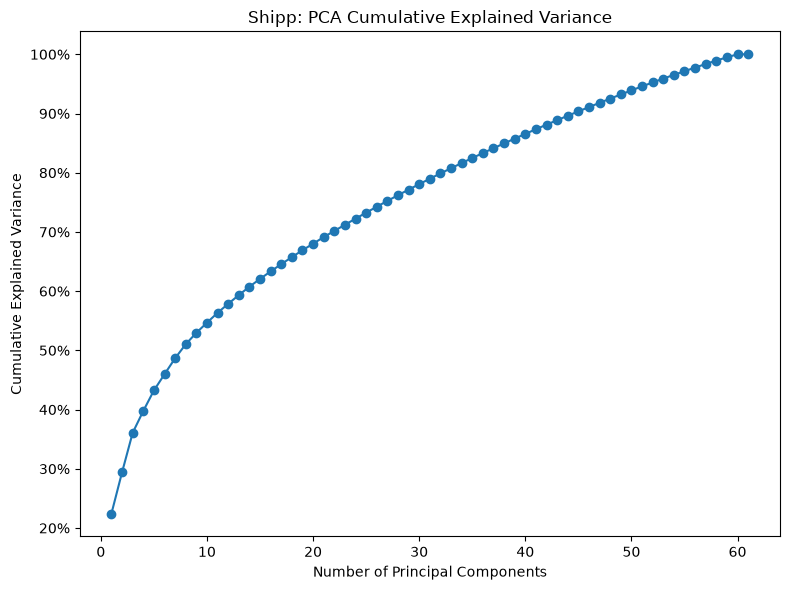

In [81]:
ratios = shipp_pca.explained_variance_ratio_
components = np.arange(1, len(ratios) + 1)
cumsum = np.cumsum(ratios)

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(components, cumsum, marker="o")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))

ax.set(
    xlabel="Number of Principal Components",
    ylabel="Cumulative Explained Variance",
    title="Shipp: PCA Cumulative Explained Variance"
)

plt.tight_layout()
plt.show()

## 11. UMAP Visualization

c:\Users\zehra\AppData\Local\Programs\Python\Python313\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


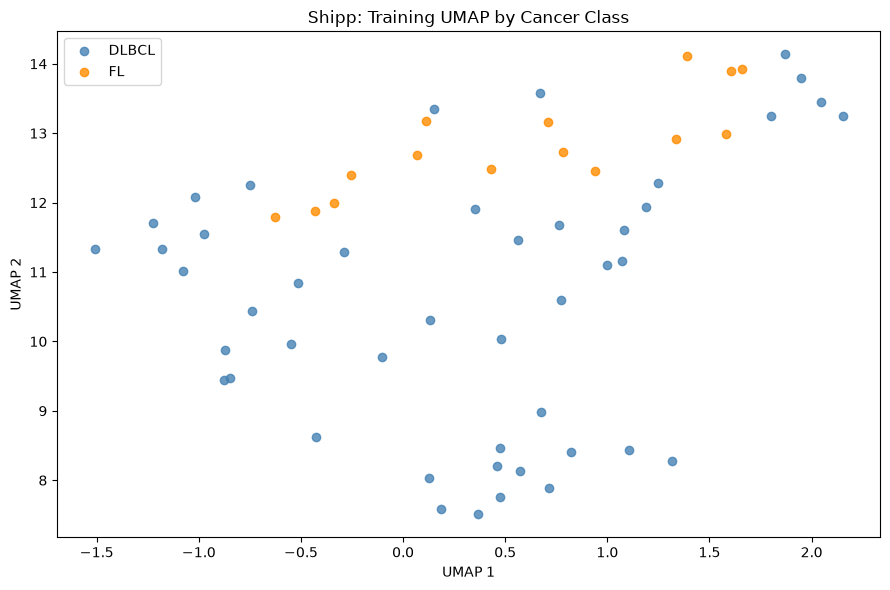

In [82]:
import umap
shipp_umap = umap.UMAP(n_neighbors=10, min_dist=0.1, random_state=SEED)
X_shipp_train_umap = shipp_umap.fit_transform(X_shipp_train_scaled)
fig, ax = plt.subplots(figsize=(9, 6))
for target, label, color in [(1, "DLBCL", "steelblue"), (0, "FL", "darkorange")]:
    mask = y_shipp_train.to_numpy() == target
    ax.scatter(X_shipp_train_umap[mask, 0], X_shipp_train_umap[mask, 1], label=label, color=color, alpha=0.8)
ax.set(title="Shipp: Training UMAP by Cancer Class", xlabel="UMAP 1", ylabel="UMAP 2")
ax.legend()
plt.tight_layout()
plt.show()

## 12. Differential Expression Analysis

### Class Subsets, Welch's t-tests, and FDR Correction

In [83]:
# Select and rank probes using training patients only.
shipp_valid_probes = X_shipp_train_log.columns[X_shipp_train_log.nunique() > 1]
dlbcl_data = X_shipp_train_log.loc[y_shipp_train == 1, shipp_valid_probes]
fl_data = X_shipp_train_log.loc[y_shipp_train == 0, shipp_valid_probes]
print("Training DLBCL:", dlbcl_data.shape)
print("Training FL:", fl_data.shape)

Training DLBCL: (46, 7129)
Training FL: (15, 7129)


In [84]:
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

t_stats, p_values = ttest_ind(dlbcl_data, fl_data, axis=0, equal_var=False)
finite = np.isfinite(p_values)
print("Invalid tests excluded:", (~finite).sum())
shipp_valid_probes = shipp_valid_probes[finite]
t_stats, p_values = t_stats[finite], p_values[finite]
dlbcl_data = dlbcl_data.loc[:, shipp_valid_probes]
fl_data = fl_data.loc[:, shipp_valid_probes]
reject, p_adjusted, _, _ = multipletests(p_values, alpha=0.05, method="fdr_bh")
print("Training probes tested:", len(p_values))
print("Significant probes (FDR < 0.05):", reject.sum())

Invalid tests excluded: 0
Training probes tested: 7129
Significant probes (FDR < 0.05): 1379


In [119]:
shipp_gene_stats = pd.DataFrame({
    "probe": shipp_valid_probes,
    "t_stat": t_stats,
    "p_value": p_values,
    "p_adjusted": p_adjusted,
    "mean_difference": dlbcl_data.mean().values - fl_data.mean().values
}).sort_values("p_adjusted")
display(shipp_gene_stats.head(20))
shipp_gene_stats = shipp_gene_stats.reset_index(drop=True)

,probe,t_stat,p_value,p_adjusted,mean_difference
3008,M63835_at,9.966761,2.919542e-14,2.081341e-10,3.300057
2352,M14159_cds2_at,-9.964654,1.096264e-13,3.907634e-10,-1.625789
5746,X17567_s_at,9.195979,3.847203e-12,9.142236e-09,0.925985
2884,M57710_at,8.207609,3.038898e-11,4.015725e-08,1.593437
5736,X16983_at,-8.182008,2.976970e-11,4.015725e-08,-1.652017
671,D78134_at,-8.697385,3.379766e-11,4.015725e-08,-0.881399
5487,X01060_at,8.056925,5.248542e-11,5.345265e-08,1.601681
838,D87119_at,-8.940670,1.040176e-10,9.269268e-08,-1.651293
5460,V00594_at,8.098031,1.740088e-10,1.127735e-07,2.840297
1696,L06132_at,7.870129,1.705736e-10,1.127735e-07,0.765014


## 13. Hierarchical Clustering of Discriminative Probes

### Top 20 Probes

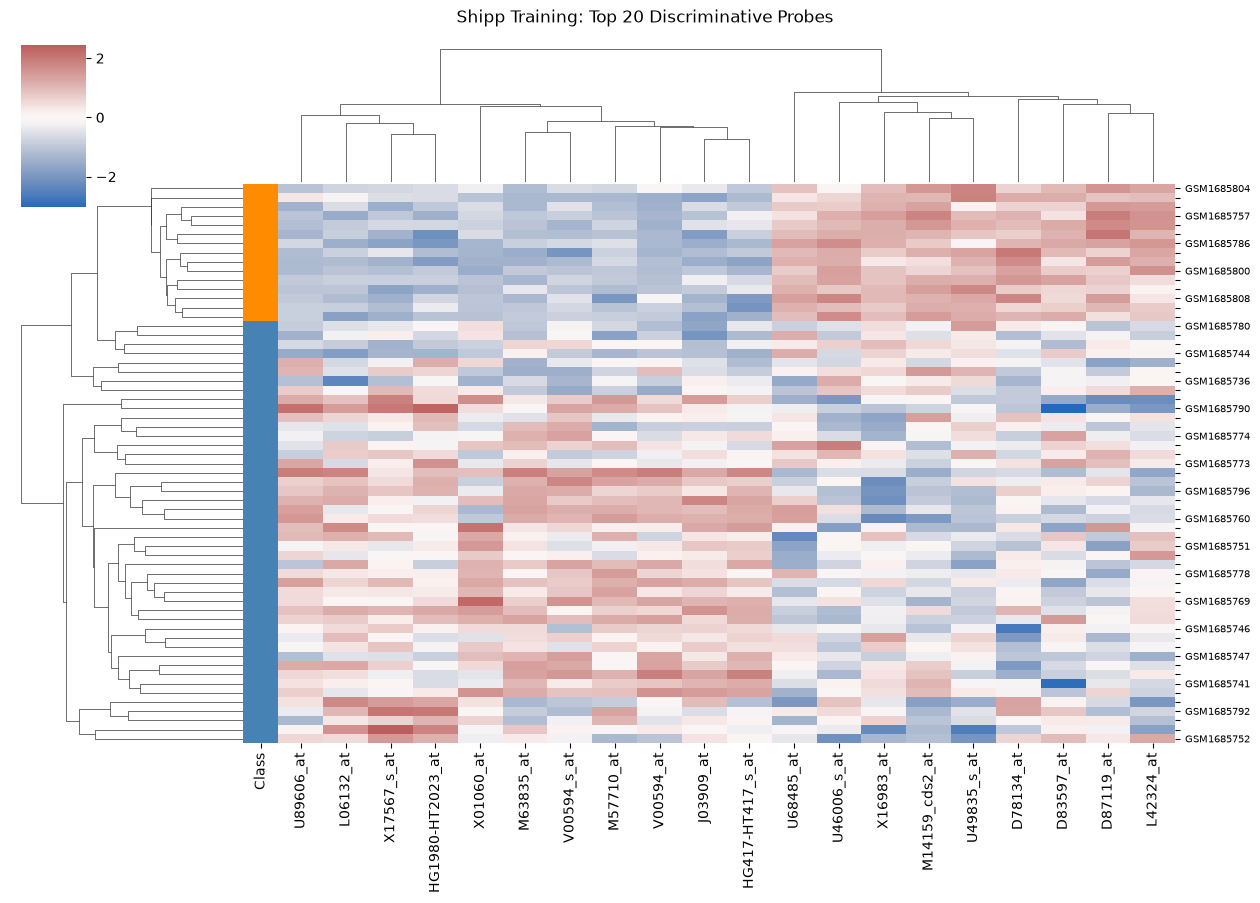

In [122]:

import seaborn as sns
import matplotlib.pyplot as plt

top20_shipp = shipp_gene_stats.head(20)["probe"]
X_shipp_top20 = X_shipp_train_log[top20_shipp]

X_shipp_top20_z = (
    X_shipp_top20 - X_shipp_top20.mean()
) / X_shipp_top20.std()

shipp_class_colors = y_shipp_train.map({
    1: "steelblue",     # DLBCL
    0: "darkorange"     # FL
}).rename("Class")

g_shipp20 = sns.clustermap(
    X_shipp_top20_z,
    row_colors=shipp_class_colors,
    cmap="vlag",
    center=0,
    method="average",
    metric="euclidean",
    figsize=(13, 9),
    xticklabels=True,
    yticklabels=True
)

# Show every third sample ID
labels = g_shipp20.ax_heatmap.get_yticklabels()

for i, label in enumerate(labels):
    label.set_visible(i % 3 == 0)

g_shipp20.ax_heatmap.tick_params(axis="y", labelsize=7)

g_shipp20.fig.suptitle(
    "Shipp Training: Top 20 Discriminative Probes",
    y=1.02
)

g_shipp20.ax_heatmap.set_xlabel("")
plt.show()


### Top 50 Probes

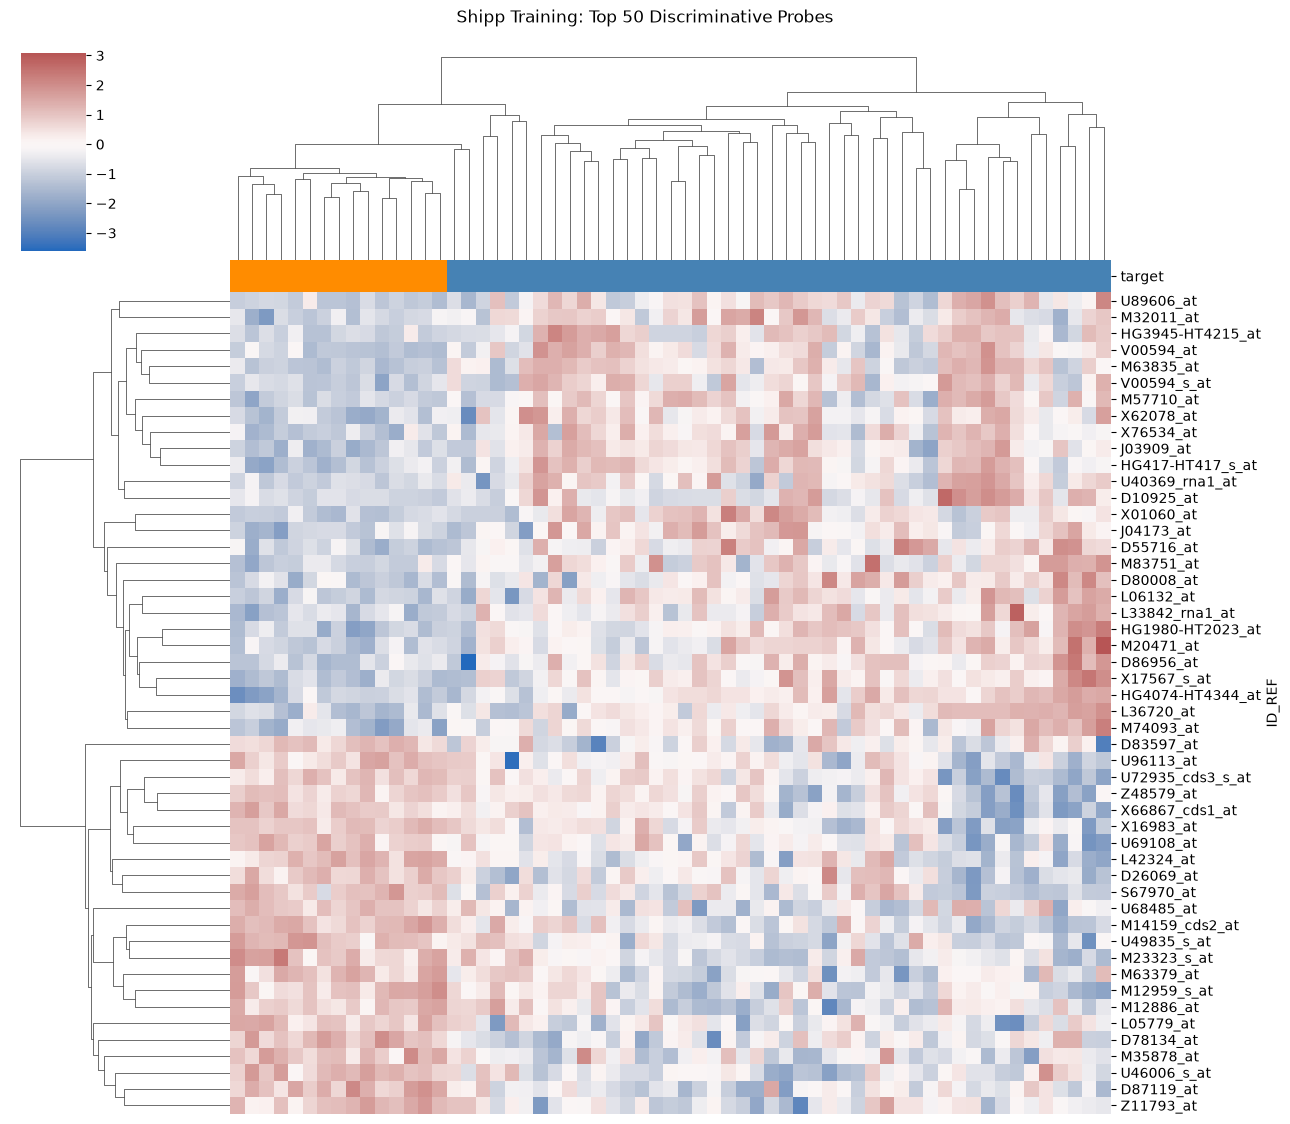

In [87]:
top50_shipp = shipp_gene_stats.head(50)["probe"]

X_shipp_top50 = X_shipp_train_log[top50_shipp]

X_shipp_top50_z = (
    X_shipp_top50 - X_shipp_top50.mean()
) / X_shipp_top50.std()

g_shipp50 = sns.clustermap(
    X_shipp_top50_z.T,
    col_colors=shipp_class_colors,
    cmap="vlag",
    center=0,
    figsize=(13, 11),
    xticklabels=False,
    yticklabels=True
)

g_shipp50.fig.suptitle(
    "Shipp Training: Top 50 Discriminative Probes",
    y=1.02
)

plt.show()

## 13. Training vs. Independent Test: Distribution Differences and Potential Batch Effects

In [88]:
shipp_mean_shifts = (X_shipp_test_log.mean() - X_shipp_train_log.mean()).abs()
print(shipp_mean_shifts.describe())
print("Median absolute gene-wise log2 shift:", shipp_mean_shifts.median())

count    7129.000000
mean        0.223645
std         0.178128
min         0.000001
25%         0.089227
50%         0.186892
75%         0.314178
max         2.190555
dtype: float64
Median absolute gene-wise log2 shift: 0.18689158302954922


### Training and Test Distributions Within Each Diagnosis

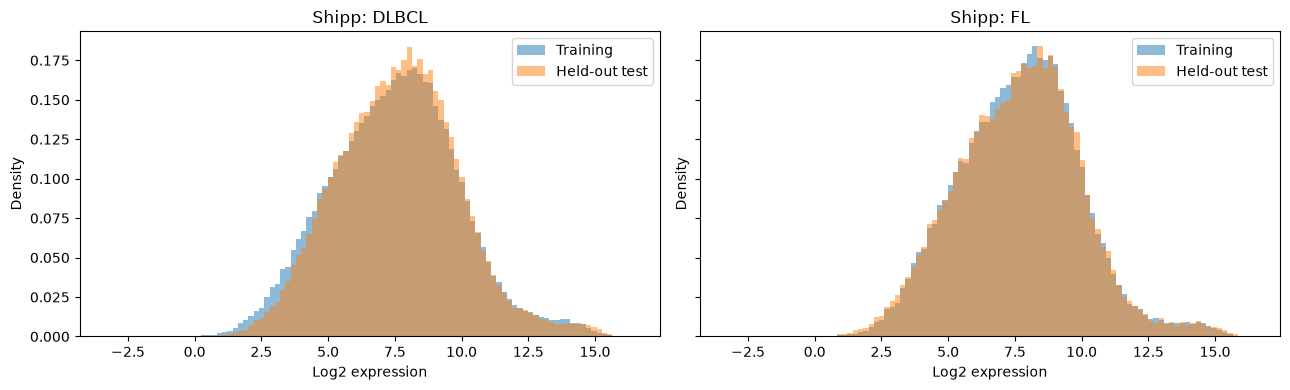

In [89]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharex=True, sharey=True)
for ax, target, diagnosis in zip(axes, [1, 0], ["DLBCL", "FL"]):
    for X, y, split in [(X_shipp_train_log, y_shipp_train, "Training"),
                         (X_shipp_test_log, y_shipp_test, "Held-out test")]:
        ax.hist(X.loc[y == target].to_numpy().ravel(), bins=shipp_log_bins,
                density=True, alpha=0.5, label=split)
    ax.set(title=f"Shipp: {diagnosis}", xlabel="Log2 expression", ylabel="Density")
    ax.legend()
plt.tight_layout()
plt.show()

### Test Projection into Training-Fitted PCA

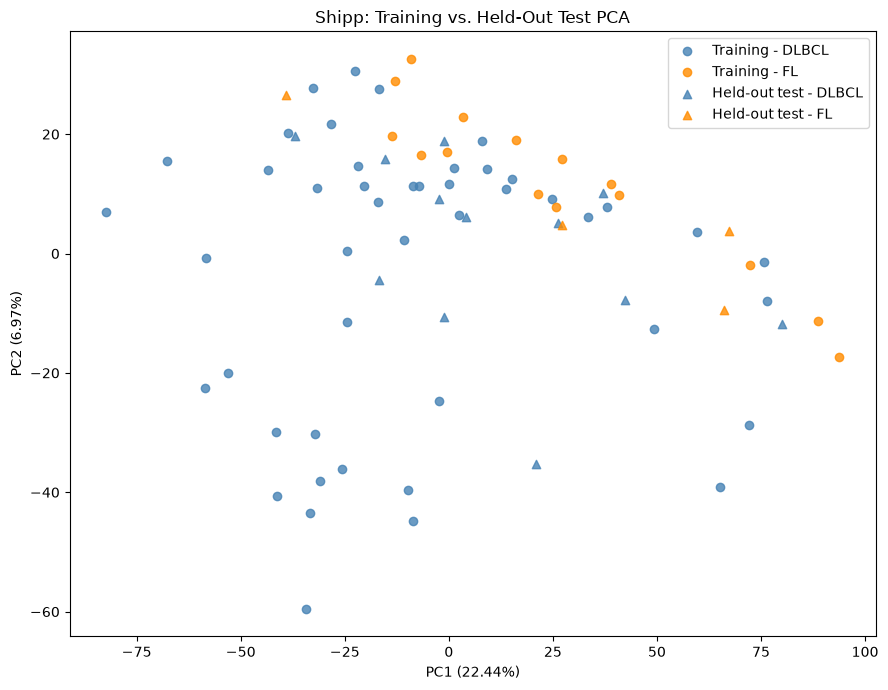

In [90]:
fig, ax = plt.subplots(figsize=(9, 7))
for coords, labels, marker, split in [
    (X_shipp_train_pca, y_shipp_train, "o", "Training"),
    (X_shipp_test_pca, y_shipp_test, "^", "Held-out test")
]:
    for target, color, diagnosis in [(1, "steelblue", "DLBCL"), (0, "darkorange", "FL")]:
        mask = labels.to_numpy() == target
        ax.scatter(coords[mask, 0], coords[mask, 1], color=color, marker=marker,
                   alpha=0.8, label=f"{split} - {diagnosis}")
ax.set_xlabel(f"PC1 ({shipp_pca.explained_variance_ratio_[0]:.2%})")
ax.set_ylabel(f"PC2 ({shipp_pca.explained_variance_ratio_[1]:.2%})")
ax.set_title("Shipp: Training vs. Held-Out Test PCA")
ax.legend()
plt.tight_layout()
plt.show()